# `ride_factor` sweep for `RideBoundedGreedyPolicy`

`RideBoundedGreedyPolicy` caps how far an onboard rider may be detoured before
the bus must deliver them. A **tight** `ride_factor` keeps rides short but, under
the wait cap, defers pickups so much that they abandon (lower served fraction);
a **loose** `ride_factor` approaches plain `NearestUnservedPolicy`
(`ride_factor = ∞`). This notebook sweeps `ride_factor` to map the
**served-fraction ↔ max-ride** frontier so we can pick an operating point.

Each swept value is its own column in the comparison, run on the **same demand
seeds** as the baselines, so the numbers are directly comparable.
`compare_policies` renders one **tqdm** progress bar (with ETA) per column.

**How to read the frontier plot:** look for the `RB rf=…` point whose served
fraction is closest to Nearest's while its max ride stays well below Nearest's.
If no such point exists, the all-pickups-off gate is too blunt and the next step
is to let cheap / en-route pickups through even when a rider is at budget.

In [1]:
%matplotlib inline

import statistics

import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from src.algorithm.FixedRoutePolicy import FixedRoutePolicy
from src.algorithm.SkipStopFixedRoutePolicy import SkipStopFixedRoutePolicy
from src.algorithm.NearestUnservedPolicy import NearestUnservedPolicy
from src.algorithm.RideBoundedGreedyPolicy import RideBoundedGreedyPolicy
from src.experiment import summarize_comparison
from src.map.PlanarMapProvider import PlanarMapProvider
from src.map.graph import PlanarStreetGraph

In [2]:
MAP_SEED = 42

graph = PlanarStreetGraph.generate(
    n_seeds=17,
    bounds=(0.0, 0.0, 2000.0, 2000.0),
    seed=MAP_SEED,
    stop_density=0.5,
)

provider = PlanarMapProvider(graph)
print(f"{len(provider.get_stops())} bus stops on this map")

21 bus stops on this map


In [3]:
# Swept ride_factor values (edit freely; add e.g. 4.0 to approach Nearest).
RIDE_FACTORS = [1.5, 2.0, 2.5, 3.0]

N_TRIALS = 1000
BASE_SEED = 0

# run_trial kwargs, matching the campus experiment.
TRIAL_KWARGS = dict(max_requests=200, capacity=40, max_wait_s=900.0)

# Baselines (Nearest is the ride_factor = ∞ anchor) plus one RideBounded column
# per swept factor. The `rf=rf` default-arg capture avoids the late-binding
# closure bug (all lambdas would otherwise see the final rf).
policies = [
    ("Fixed route", lambda g: FixedRoutePolicy(g)),
    ("Fixed route w/ skip", lambda g: SkipStopFixedRoutePolicy(g)),
    ("Nearest unserved", lambda g: NearestUnservedPolicy(g)),
] + [
    (f"RB rf={rf}", lambda g, rf=rf: RideBoundedGreedyPolicy(g, ride_factor=rf))
    for rf in RIDE_FACTORS
]

summary = summarize_comparison(
    policies=policies,
    graph=graph,
    n_trials=N_TRIALS,
    base_seed=BASE_SEED,
    **TRIAL_KWARGS,
)

display(Markdown(summary.markdown))

Fixed route        :   0%|          | 0/1000 [00:00<?, ?it/s]

Fixed route w/ skip:   0%|          | 0/1000 [00:00<?, ?it/s]

Nearest unserved   :   0%|          | 0/1000 [00:00<?, ?it/s]

RB rf=1.5          :   0%|          | 0/1000 [00:00<?, ?it/s]

RB rf=2.0          :   0%|          | 0/1000 [00:00<?, ?it/s]

RB rf=2.5          :   0%|          | 0/1000 [00:00<?, ?it/s]

RB rf=3.0          :   0%|          | 0/1000 [00:00<?, ?it/s]

| Property | Fixed route | Fixed route w/ skip | Nearest unserved | RB rf=1.5 | RB rf=2.0 | RB rf=2.5 | RB rf=3.0 |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Fulfilled requests | 136.6 (±0.4%) | 141.3 (±0.8%) | 146.4 (±0.8%) | 125.0 (±0.8%) | 133.7 (±0.8%) | 139.2 (±0.8%) | 141.1 (±0.8%) |
| Cancelled requests | 63.0 (±0.7%) | 55.9 (±1.1%) | 50.8 (±1.1%) | 72.2 (±1.0%) | 63.5 (±1.1%) | 58.0 (±1.1%) | 56.1 (±1.1%) |
| Mean wait time | 453.0 s (±0.4%) | 460.8 s (±0.8%) | 366.3 s (±0.8%) | 399.2 s (±0.8%) | 385.2 s (±0.8%) | 377.3 s (±0.8%) | 375.4 s (±0.8%) |
| P90 wait time | 805.8 s (±0.3%) | 796.5 s (±0.8%) | 676.8 s (±0.8%) | 732.9 s (±0.8%) | 712.7 s (±0.8%) | 700.5 s (±0.8%) | 698.1 s (±0.8%) |
| Mean ride time | 654.4 s (±0.4%) | 585.1 s (±0.8%) | 1003.3 s (±1.5%) | 515.9 s (±1.2%) | 662.4 s (±1.5%) | 796.0 s (±1.7%) | 841.6 s (±1.7%) |
| Fulfillment rate | 68.5 % (±0.3%) | 72.0 % (±0.4%) | 74.6 % (±0.4%) | 63.9 % (±0.6%) | 68.2 % (±0.5%) | 71.0 % (±0.4%) | 72.0 % (±0.4%) |
| Served fraction | 68.5 % (±0.3%) | 72.0 % (±0.4%) | 74.6 % (±0.4%) | 63.9 % (±0.6%) | 68.2 % (±0.5%) | 71.0 % (±0.4%) | 72.0 % (±0.4%) |
| Throughput | 0.6 req/min (±0.9%) | 0.7 req/min (±3.4%) | 0.7 req/min (±3.3%) | 0.6 req/min (±3.9%) | 0.7 req/min (±3.6%) | 0.7 req/min (±3.5%) | 0.7 req/min (±3.4%) |
| Tick snapshots | 13447.3 (±0.3%) | 12958.9 (±0.7%) | 12879.1 (±0.7%) | 12842.0 (±0.7%) | 12866.6 (±0.7%) | 12873.6 (±0.7%) | 12881.7 (±0.7%) |
| Fulfilled (wait samples) | 136.6 (±0.4%) | 141.3 (±0.8%) | 146.4 (±0.8%) | 125.0 (±0.8%) | 133.7 (±0.8%) | 139.2 (±0.8%) | 141.1 (±0.8%) |
| Min wait time | 7.6 s (±6.0%) | 6.5 s (±7.0%) | 6.2 s (±7.1%) | 7.2 s (±7.4%) | 6.2 s (±7.4%) | 6.8 s (±7.5%) | 6.4 s (±7.1%) |
| Max wait time | 891.6 s (±0.3%) | 880.4 s (±0.7%) | 869.6 s (±0.7%) | 873.6 s (±0.7%) | 872.7 s (±0.7%) | 871.9 s (±0.7%) | 871.2 s (±0.7%) |
| Min ride time | 11.7 s (±4.6%) | 11.3 s (±4.6%) | 8.1 s (±2.5%) | 7.8 s (±3.0%) | 7.9 s (±2.8%) | 8.0 s (±2.7%) | 8.0 s (±2.6%) |
| Max ride time | 1300.8 s (±0.3%) | 1277.3 s (±0.8%) | 10219.6 s (±1.5%) | 3992.1 s (±2.3%) | 5856.5 s (±2.4%) | 7621.0 s (±2.2%) | 8183.2 s (±2.2%) |

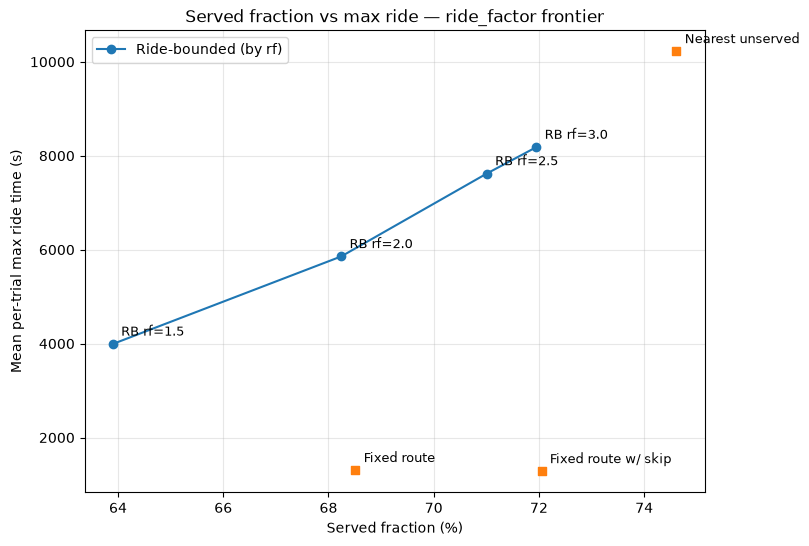

In [4]:
# Frontier: mean served fraction (x) vs mean per-trial max ride (y) per policy.
def _mean_served(trials):
    values = [
        t.kpi.served_fraction
        for t in trials
        if t.kpi.served_fraction is not None
    ]
    return statistics.fmean(values) if values else None


def _mean_max_ride(trials):
    per_trial_max = [max(t.ride_times) for t in trials if t.ride_times]
    return statistics.fmean(per_trial_max) if per_trial_max else None


points = {
    label: (_mean_served(trials), _mean_max_ride(trials))
    for label, trials in summary.results.items()
}
points = {
    label: (served, max_ride)
    for label, (served, max_ride) in points.items()
    if served is not None and max_ride is not None
}

rb_labels = [f"RB rf={rf}" for rf in RIDE_FACTORS if f"RB rf={rf}" in points]
baseline_labels = [label for label in points if label not in rb_labels]

fig, ax = plt.subplots(figsize=(8, 6))

# RideBounded frontier: connect points in ride_factor order.
rb_x = [points[label][0] * 100.0 for label in rb_labels]
rb_y = [points[label][1] for label in rb_labels]
ax.plot(rb_x, rb_y, "-o", color="tab:blue", label="Ride-bounded (by rf)")

# Baselines as separate markers.
for label in baseline_labels:
    served, max_ride = points[label]
    ax.scatter(served * 100.0, max_ride, marker="s", color="tab:orange", zorder=3)

for label, (served, max_ride) in points.items():
    ax.annotate(
        label,
        (served * 100.0, max_ride),
        textcoords="offset points",
        xytext=(6, 6),
        fontsize=9,
    )

ax.set_xlabel("Served fraction (%)")
ax.set_ylabel("Mean per-trial max ride time (s)")
ax.set_title("Served fraction vs max ride — ride_factor frontier")
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()

## Choosing an operating point

- **Up and to the right is coverage; down is short rides.** As `ride_factor`
  grows, the blue frontier should move from bottom-left (rf=1.5: low served, low
  max ride) toward the **Nearest** marker (`ride_factor = ∞`).
- **A good operating point** is a `RB rf=…` point whose served fraction is close
  to Nearest's (ideally within ~1–2 pp) while its max ride stays well below
  Nearest's — that keeps most of the ride win for a small coverage cost.
- **If no such point exists** (every factor that cuts the ride tail also drops
  served fraction sharply), the frontier is unfavourable: the coarse
  all-pickups-off gate is too blunt. The next step would be refining the gate to
  allow a cheap / en-route pickup even while a rider is at budget, which should
  bend the frontier outward.
- Remember served fraction is geometry-capped (~76% here); if coverage is the
  sole objective, plain Nearest is hard to beat and the ride cap only pays off
  when long rides are themselves a cost.